# Unidad 39 — Mini proyecto de análisis de datos financieros

Semana 6 · Clase 2 · Fuente: PDF parte 2, págs. 4–56

[Índice de la semana](../semana-06.ipynb) | [Anterior](../clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb) | [Siguiente](u40-pandemia-coronavirus.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el docente y el PDF (págs. 6–7):

- Adquirir y procesar datos financieros desde repositorios remotos (Yahoo Finanzas).
- Visualizar precios y volúmenes de negociación como series temporales.
- Calcular el cambio porcentual diario, el rendimiento acumulado y la volatilidad.
- Analizar la correlación entre distintos activos (por ejemplo, durante la pandemia de COVID-19).

**Referencia:** PDF parte 2, págs. 6–7

## Contexto

Pandas se creó originalmente para analizar y organizar datos financieros. Por eso el análisis de datos financieros es, según el PDF, la práctica más eficaz para consolidar lo aprendido: obliga a obtener datos de una fuente externa, limpiarlos, transformarlos, graficarlos y sacar conclusiones.

El proyecto usa datos del mercado estadounidense, que tiene un gran impacto en la economía real del mundo. No se analiza una sola empresa: se eligen siete **fondos cotizados (ETF)** que representan sectores y condiciones económicas distintas. Cada uno se identifica con su **ticker** (código de cotización).

| Ticker | Qué sigue |
|---|---|
| `SPY` | El principal índice estadounidense, S&P 500 |
| `IYW` | Empresas tecnológicas estadounidenses (capitalización bursátil) |
| `VT` | Empresas de todo el mundo |
| `DBA` | Oferta, demanda y precios de productos agrícolas |
| `TLT` | Bonos del Tesoro de Estados Unidos (largo plazo) |
| `PDBC` | Otras materias primas (oferta, demanda y precios) |
| `IAU` | Oro |

Las tareas del proyecto (PDF, pág. 7) son: obtener datos remotos, graficar precios y volumen, medir la variación diaria, calcular el rendimiento acumulado, calcular la media móvil, analizar la correlación entre activos y calcular la volatilidad.

**Vocabulario vital:**

- **Ticker:** código corto que identifica un valor en el mercado (por ejemplo, `SPY`).
- **Serie temporal:** datos ordenados por fecha; en pandas, un `DataFrame` con `DatetimeIndex`.
- **Cambio porcentual diario:** `(hoy - ayer) / ayer * 100`.
- **Coeficiente de correlación:** medida de la asociación entre dos series, entre -1 y 1 (`.corr()`).

**Referencia:** PDF parte 2, págs. 6–8

### Cómo se obtienen y se guardan los datos en este cuaderno

El PDF descarga los datos en vivo con la biblioteca `yfinance`. Este cuaderno debe ejecutarse sin conexión y con resultados estables, así que los datos ya se descargaron una sola vez y se guardaron en archivos CSV pequeños dentro de la carpeta `datos/` de la semana:

| Archivo | Contenido |
|---|---|
| `u39-dis.csv` | Datos de Disney (`DIS`): apertura, máximo, mínimo, cierre y volumen (Paso 1) |
| `u39-cierre.csv` | Precio de cierre diario de los siete tickers (Pasos 2 a 9) |
| `u39-pdbc.csv` | Cierre y volumen diario de `PDBC` (Pasos 4 y 5) |

Rango: desde el 2020-01-02 hasta el 2021-11-09, el mismo que usa el PDF (inicio el 1 de enero de 2020; el PDF se creó en noviembre de 2021).

**Nota sobre el PDF:** el PDF usa `end = datetime.today()`, así que cada ejecución da un rango distinto y los números cambian con el tiempo. Aquí se fija el final en `2021-11-10` (excluido) para que los resultados sean reproducibles. Además, el PDF muestra una primera fila `2019-12-31` por un desfase de zona horaria de la versión antigua de la herramienta; con la versión actual la serie comienza el `2020-01-02`, el primer día de operación de 2020. Por último, la versión actual de `yfinance` devuelve el cierre **ya ajustado** por dividendos y divisiones (`auto_adjust=True`) y no trae la columna `Adj Close`; por eso los precios absolutos difieren un poco de los del PDF, pero las variaciones y correlaciones son casi iguales.

## 1. Paso 1 — Librerías y función de adquisición de datos

El PDF empieza instalando la biblioteca de acceso a Yahoo Finanzas e importando lo necesario:

```python
!pip install yfinance        # en este proyecto ya está instalada con uv
```

Luego define una función que recibe un ticker y un rango de fechas y devuelve un `DataFrame`:

- Línea 2: `yf.Ticker(ticker).history(start=start, end=end)` lee los datos de Yahoo Finanzas.
- Línea 3: `data.insert(0, "Ticker", ticker)` crea una columna `Ticker` en la posición 0 con el nombre del ticker en cada fila (se necesitará más adelante para pivotar).

**Referencia:** PDF parte 2, págs. 10–11

In [2]:
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
import yfinance as yf          # solo se usa en el código de referencia no ejecutado

from datetime import date, datetime, time, timezone

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


La función del PDF y su uso con Disney se muestran a continuación **sin ejecutar** (requieren conexión a Internet). Es el código tal cual del PDF; en la siguiente celda se leen los datos ya guardados.

```python
def get_stock_data(ticker, start, end):
    data = yf.Ticker(ticker).history(start=start, end=end)
    data.insert(0, "Ticker", ticker)
    return data

ticker = 'DIS'
start = datetime(2020, 1, 1)
end = datetime.today()          # en este cuaderno se fijó en datetime(2021, 11, 10)

d = get_stock_data(ticker, start, end)
d.head()
```

- La búsqueda del ticker se puede hacer en Yahoo Finance o en investing.com.
- `start` y `end` se pueden indicar como marcas de tiempo (`datetime`) o como fechas concretas; `end` queda **excluido**.

**Nota sobre el PDF:** el PDF muestra las columnas `Ticker, High, Low, Open, Close, Volume, Adj Close`. La versión actual de `yfinance` devuelve `Open, High, Low, Close, Volume, Dividends, Stock Splits` (y el índice con zona horaria `America/New_York`). Para guardar los datos en CSV se quitó la zona horaria y las columnas que no se usan, y se redondearon los precios a 4 decimales.

In [3]:
# Datos de Disney descargados previamente con get_stock_data("DIS", ...) y guardados en CSV
d = pd.read_csv("../datos/u39-dis.csv", index_col="Date", parse_dates=True)
d.head()

,Ticker,Open,High,Low,Close,Volume
Date,,,,,,
2020-01-02,DIS,140.8678,143.6893,140.6836,143.6893,9502100
2020-01-03,DIS,141.9441,143.3984,141.6047,142.0410,7320200
2020-01-06,DIS,141.1102,141.5853,139.9177,141.2169,8262500
2020-01-07,DIS,141.5465,142.3997,140.9939,141.2653,6906500
2020-01-08,DIS,141.0618,141.6823,140.4122,140.9745,6984200


La columna `Date` es el índice y es de tipo fecha: por eso se puede cortar por fechas y graficar como serie temporal. Como el análisis solo usa el precio de cierre de cada ticker, el PDF **pivota** el `DataFrame`: cada valor distinto de `Ticker` se convierte en una columna y sus valores son los de `Close`.

In [4]:
d = d.pivot(columns="Ticker", values="Close")
d.head()

Ticker,DIS
Date,
2020-01-02,143.6893
2020-01-03,142.0410
2020-01-06,141.2169
2020-01-07,141.2653
2020-01-08,140.9745


**Clave:** `pivot(columns="Ticker", values="Close")` convierte el formato largo (una fila por ticker y fecha) en formato ancho (una fila por fecha, una columna por ticker). Con un solo ticker parece innecesario, pero se vuelve fundamental al combinar siete.

**Error común:** olvidar la columna `Ticker` en la función de descarga; sin ella, al juntar varios tickers no se sabe a cuál pertenece cada fila.

**Referencia:** PDF parte 2, págs. 10–14

## 2. Paso 2 — Un marco de datos por ticker y su unión con `concat()`

El PDF crea un `DataFrame` por cada ticker llamando a la función siete veces, y los nombra con el ticker:

```python
SPY = get_stock_data("SPY", start, end)
IYW = get_stock_data("IYW", start, end)
VT  = get_stock_data("VT",  start, end)
DBA = get_stock_data("DBA", start, end)
TLT = get_stock_data("TLT", start, end)
PDBC = get_stock_data("PDBC", start, end)
IAU = get_stock_data("IAU", start, end)
```

`SPY.info()` confirma que es un `DatetimeIndex` y que no hay valores nulos. Después se pivota cada uno (`index=None` usa el índice existente, la fecha):

```python
SPY = SPY.pivot(index=None, columns="Ticker", values="Close")   # forma del PDF; en pandas 3.1 se escribe sin index
# ... lo mismo para IYW, VT, DBA, TLT, PDBC e IAU
```

Y finalmente se combinan en un solo `DataFrame` con `pd.concat`:

```python
stock = pd.concat([SPY, IYW, VT, DBA, TLT, PDBC, IAU], axis=1, join='outer')
```

El PDF explica la firma `pandas.concat(objs, axis=0, join='outer', ...)` y las opciones usadas:

- Línea 1: la lista de marcos de datos a concatenar.
- `axis=1`: se unen **lado a lado** (por columnas). El valor por defecto es `axis=0`, que apila verticalmente.
- `join='outer'`: se conserva la unión de los índices; con `join='inner'` quedaría solo la intersección. Es el valor por defecto.

Antes de concatenar hay que comprobar que los marcos tengan el mismo índice, las mismas columnas y los mismos tipos; aquí lo cumplen, por lo que la unión mantiene la coherencia de los datos.

**Nota sobre el PDF:** en la pág. 19 la explicación de la línea 2 describe el valor por defecto (`axis=0`, apilar verticalmente), pero el código usa `axis=1`, que une por columnas; hay que leerla como una aclaración de la firma y no como lo que hace este código. Además, la traducción escribe "interior" y "exterior" para los valores `'inner'` y `'outer'` de `join`.

**Referencia:** PDF parte 2, págs. 15–19

En este cuaderno los datos ya vienen en formato ancho en `u39-cierre.csv`. Para reproducir fielmente el flujo del PDF (marco por ticker, pivot, concat), primero se reconstruyen los siete marcos en formato largo a partir del CSV y luego se ejecutan exactamente los pasos del PDF. 

**Ampliación (no está en el PDF):** la reconstrucción es solo un recurso didáctico para poder ejecutar `pivot` y `concat` sin conexión.

In [5]:
ancho = pd.read_csv("../datos/u39-cierre.csv", index_col="Date", parse_dates=True)

def marco_largo(ticker):
    """Reconstruye el marco en formato largo (columnas Ticker y Close) que devolvería get_stock_data."""
    return pd.DataFrame({"Ticker": ticker, "Close": ancho[ticker]})

SPY = marco_largo("SPY")
IYW = marco_largo("IYW")
VT = marco_largo("VT")
DBA = marco_largo("DBA")
TLT = marco_largo("TLT")
PDBC = marco_largo("PDBC")
IAU = marco_largo("IAU")

SPY.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 469 entries, 2020-01-02 to 2021-11-09
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Ticker  469 non-null    str    
 1   Close   469 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.0 KB


In [6]:
# Con la versión actual de pandas, la forma del PDF (index=None) lanza un error
try:
    SPY.pivot(index=None, columns="Ticker", values="Close")
except KeyError as error:
    print("KeyError:", error)

KeyError: "The following 'index' labels are not columns of the DataFrame: [None]"


**Nota sobre el PDF:** el PDF escribe `pivot(index=None, columns="Ticker", values="Close")`. En pandas 3.1 pasar `index=None` de forma explícita lanza `KeyError`, porque se interpreta como una etiqueta de columna llamada `None`. La forma correcta es **omitir** `index`: cuando falta, `pivot` usa el índice existente (la fecha), que es justo lo que quería el PDF.

In [7]:
# Ejecutar el pivote por marco de datos (sin index: se usa el índice de fechas)
SPY = SPY.pivot(columns="Ticker", values="Close")
IYW = IYW.pivot(columns="Ticker", values="Close")
VT = VT.pivot(columns="Ticker", values="Close")
DBA = DBA.pivot(columns="Ticker", values="Close")
TLT = TLT.pivot(columns="Ticker", values="Close")
PDBC = PDBC.pivot(columns="Ticker", values="Close")
IAU = IAU.pivot(columns="Ticker", values="Close")

stock = pd.concat([SPY, IYW, VT, DBA, TLT, PDBC, IAU],
                  axis=1,
                  join='outer')
stock.head()

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Date,,,,,,,
2020-01-02,295.3918,57.8005,71.8010,14.5602,111.5526,8.4301,29.22
2020-01-03,293.1551,57.2235,71.1515,14.3926,113.2705,8.5010,29.62
2020-01-06,294.2734,57.5765,71.4148,14.4279,112.6273,8.5112,29.92
2020-01-07,293.4460,57.5984,71.1954,14.4632,112.0736,8.4960,30.04
2020-01-08,295.0100,58.1730,71.4850,14.3926,111.3327,8.3795,29.82


In [8]:
print("Forma:", stock.shape)
print("Valores nulos:", int(stock.isna().sum().sum()))
print("Primer día:", stock.index.min().date(), "| último día:", stock.index.max().date())
print("La unión coincide con el CSV original:", stock.equals(ancho))

Forma: (469, 7)
Valores nulos: 0
Primer día: 2020-01-02 | último día: 2021-11-09
La unión coincide con el CSV original: True


**Clave:** `concat(..., axis=1, join='outer')` alinea los marcos por el índice (fecha) y pone cada ticker en su propia columna. El resultado, `stock`, es el único `DataFrame` que se usa en el resto del análisis.

**Error común:** concatenar con `axis=0` (el valor por defecto) cuando se quería unir por columnas: se obtienen filas apiladas y muchos `NaN`.

**Para el quiz:** `pd.concat([...], axis=1, join='outer')` combina varios marcos de datos con el mismo índice en uno solo, columna por columna.

**Referencia:** PDF parte 2, págs. 15–19

## 3. Paso 3 — Gráfico de precios de cierre como serie temporal

Al graficar el precio de cierre contra la fecha se observa el movimiento de cada activo. Al superponer todos los tickers se aprecia la correlación aproximada. El PDF usa el estilo `ggplot` de matplotlib:

```python
plt.style.use('ggplot')
stock.plot(figsize=(20, 10))
plt.show()
```

- Línea 1: especifica el estilo del gráfico.
- `stock.plot()` dibuja una línea por columna usando el índice de fechas como eje horizontal.

**Referencia:** PDF parte 2, pág. 20

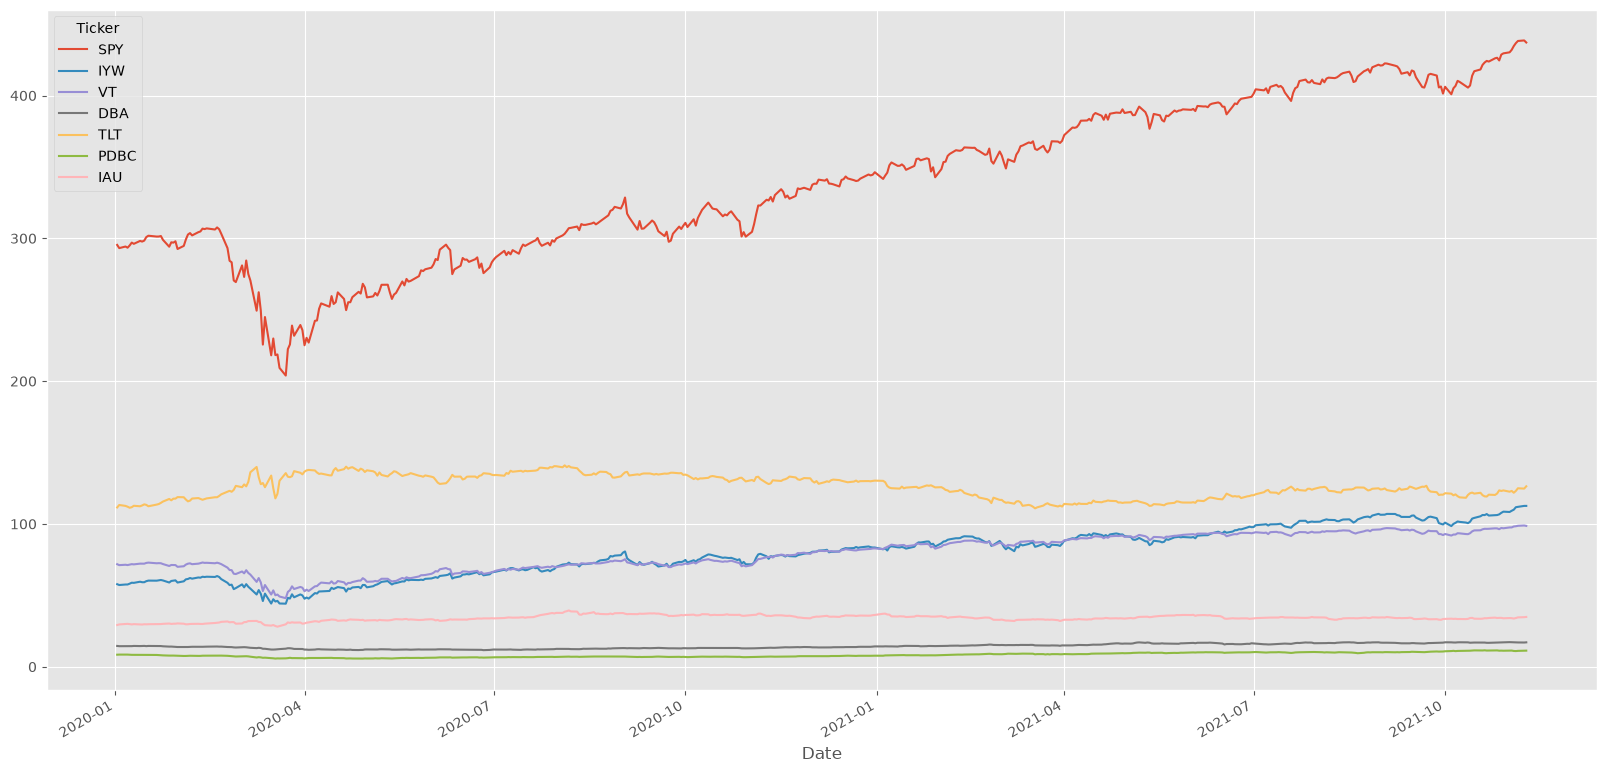

In [9]:
plt.style.use('ggplot')
stock.plot(figsize=(20, 10))
plt.show()

En el gráfico hay un tramo con fluctuaciones muy fuertes: es el periodo en que comenzó la crisis del coronavirus (COVID-19). Para estudiarlo se corta la serie con el índice de fechas (**slicing por fechas**) solo en ese periodo, entre febrero y julio de 2020:

```python
covid = stock['2020-2-1':'2020-7-31']
```

Con un `DatetimeIndex`, el corte por fechas **incluye los dos extremos**, a diferencia del corte por posición. El PDF vuelve a graficar solo ese tramo: hay activos que se ven fuertemente afectados por el choque de la pandemia y otros que apenas reaccionan.

**Referencia:** PDF parte 2, págs. 21–22

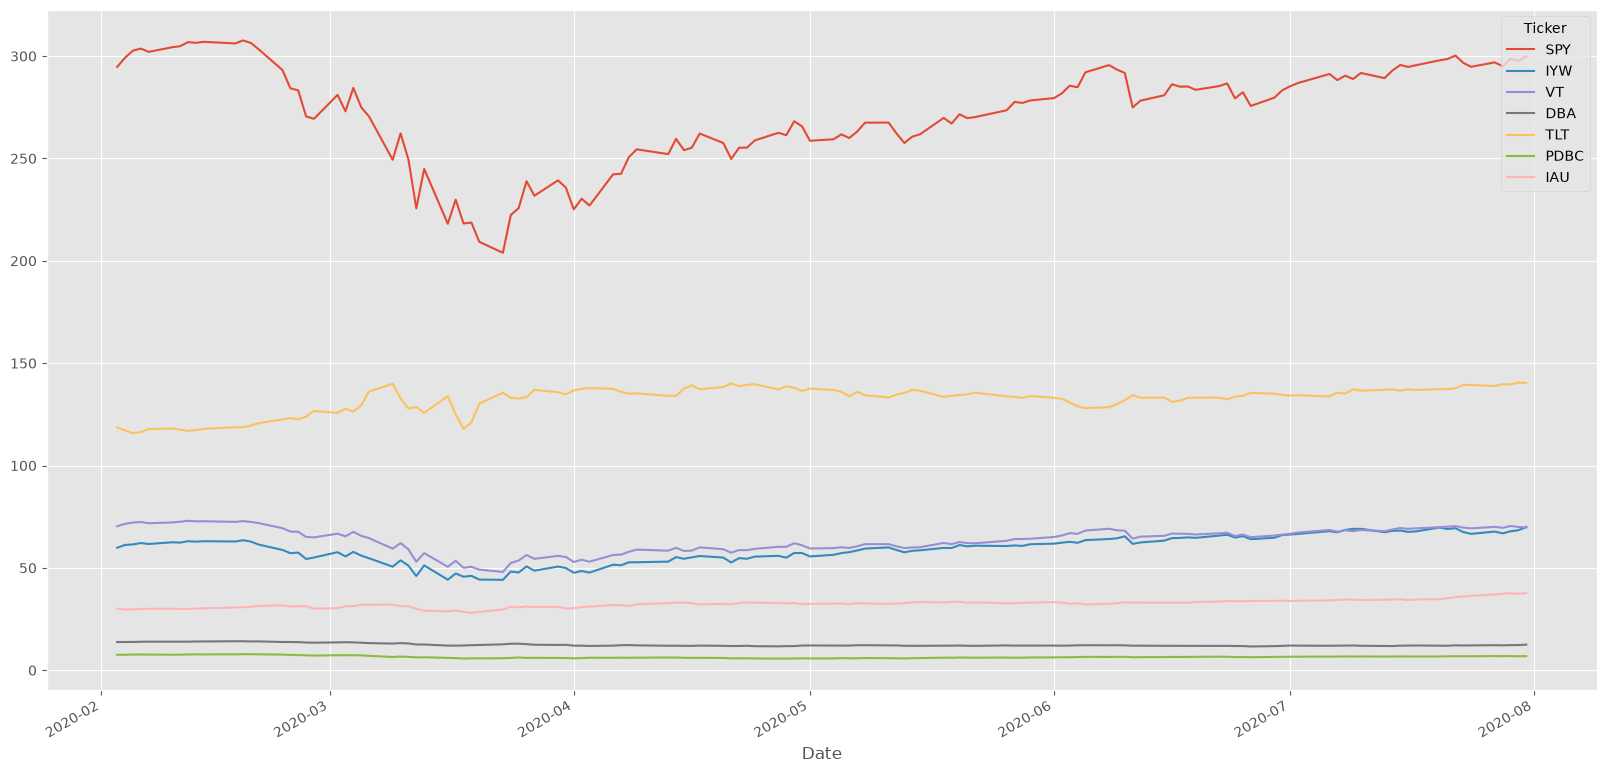

Días en el periodo: 126 | desde 2020-02-03 hasta 2020-07-31


In [10]:
covid = stock['2020-2-1':'2020-7-31']

plt.style.use('ggplot')
covid.plot(figsize=(20, 10))
plt.show()

print("Días en el periodo:", len(covid), "| desde", covid.index.min().date(), "hasta", covid.index.max().date())

Para comparar activos de personalidad distinta se separan tres series y se grafican en una fila de tres gráficos (`plt.subplots(1, 3)`):

- Línea 2 del PDF: `s_y = covid[['SPY']]` (acciones: índice S&P 500).
- `i_y = covid[['IAU']]` (oro).
- `t_y = covid[['TLT']]` (bonos del Tesoro).
- `d_y = covid[['DBA']]` (agrícolas): el PDF la define, pero no la grafica.

El PDF concluye que el precio de las acciones cae bruscamente y luego se recupera de forma gradual, mientras que el oro y los bonos se comportan de manera contraria; en particular, los bonos se mueven en dirección opuesta a las acciones.

**Referencia:** PDF parte 2, págs. 23–25

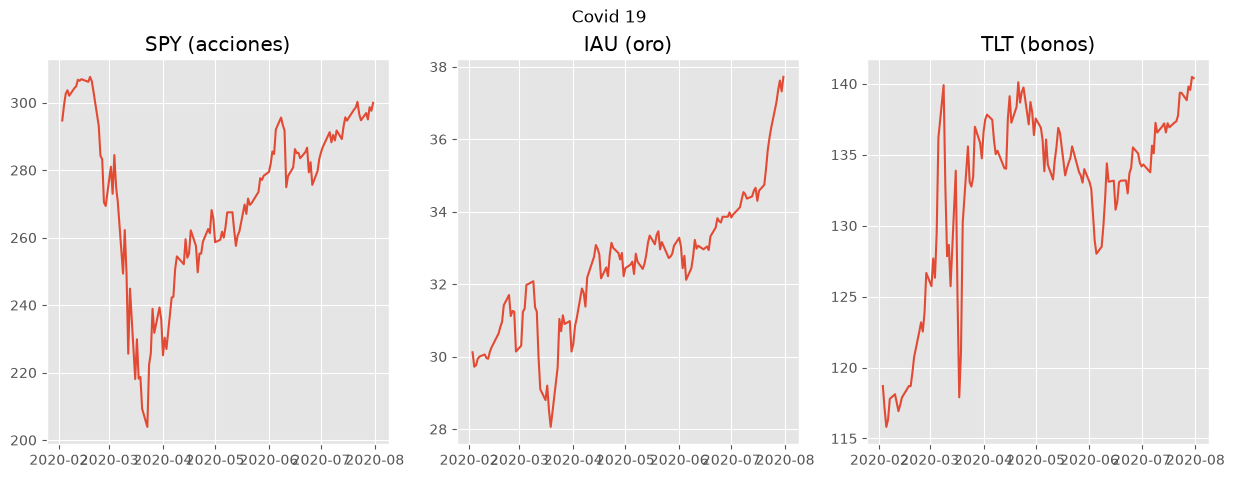

In [11]:
x = covid.index
s_y = covid[['SPY']]
i_y = covid[['IAU']]
d_y = covid[['DBA']]
t_y = covid[['TLT']]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].plot(x, s_y)
axs[1].plot(x, i_y)
axs[2].plot(x, t_y)
axs[0].set_title("SPY (acciones)")
axs[1].set_title("IAU (oro)")
axs[2].set_title("TLT (bonos)")

fig.suptitle('Covid 19')
plt.show()

**Nota sobre el PDF:** el PDF muestra la salida `Text(0.5, 0.98, 'Covid 19')`, que es el valor de retorno de `fig.suptitle`, no un gráfico adicional. En el código de arriba se añadieron títulos a cada eje (`set_title`) para identificar qué ticker es cada gráfico; el resto es idéntico al PDF. La escala vertical de cada gráfico es distinta, así que se comparan las formas y no los valores absolutos.

**Ampliación (no está en el PDF):** para medir cuánto cayó cada activo en el choque de la pandemia se puede comparar el mínimo del periodo con el cierre del primer día. Los precios guardados están ajustados, por lo que los porcentajes son aproximados.

In [12]:
# Caída máxima desde el inicio del periodo, en porcentaje, para cada ticker
caida_maxima = (covid.min() / covid.iloc[0] - 1) * 100
print(caida_maxima.round(1).sort_values())

Ticker
VT     -31.8
SPY    -30.8
IYW    -26.2
PDBC   -24.6
DBA    -15.7
IAU     -6.8
TLT     -2.4
dtype: float64


**Clave:** cortar un `DataFrame` con `df['inicio':'fin']` es la forma natural de aislar un episodio (como la pandemia) dentro de una serie temporal.

**Para el quiz:** acciones y oro/bonos reaccionan de forma distinta al choque de COVID-19: las acciones caen y se recuperan; los bonos tienden a moverse en sentido opuesto.

**Referencia:** PDF parte 2, págs. 20–25

## 4. Paso 4 — Volumen de negociación en un gráfico de barras

Para ver el **volumen de negociación** de un ticker concreto el PDF elige `PDBC` (materias primas), con el mismo rango de fechas. Se vuelve a llamar a `get_stock_data`, se borran todas las columnas excepto `Volume` y se grafica con `plt.bar`:

```python
ticker = 'PDBC'
start = datetime(2020, 1, 1)
end = datetime.today()

d = get_stock_data(ticker, start, end)
df.drop(['Ticker', 'High', 'Low', 'Open', 'Close', 'Dividends', 'Stock Splits', 'Capital Gains'],
        axis=1, inplace=True)
```

**Nota sobre el PDF:** en la pág. 28 el PDF muestra el encabezado de `DIS`, no de `PDBC`, y usa nombres de variable distintos (`d` en una celda, `df` en la siguiente). Es un arrastre del Paso 1. Además, `inplace=True` está en desuso en pandas actual; es más claro y seguro quedarse solo con la columna deseada, como se hace abajo. En el PDF el resultado final es un `DataFrame` `df` de una sola columna, `Volume`.

**Referencia:** PDF parte 2, págs. 26–29

In [13]:
# Cierre y volumen de PDBC descargados previamente con get_stock_data("PDBC", ...)
df = pd.read_csv("../datos/u39-pdbc.csv", index_col="Date", parse_dates=True)

# En lugar de df.drop([...], inplace=True) se conserva solo la columna Volume
volumen = df[["Volume"]]
volumen.head()

,Volume
Date,
2020-01-02,4004600
2020-01-03,760200
2020-01-06,1608700
2020-01-07,1723200
2020-01-08,923300


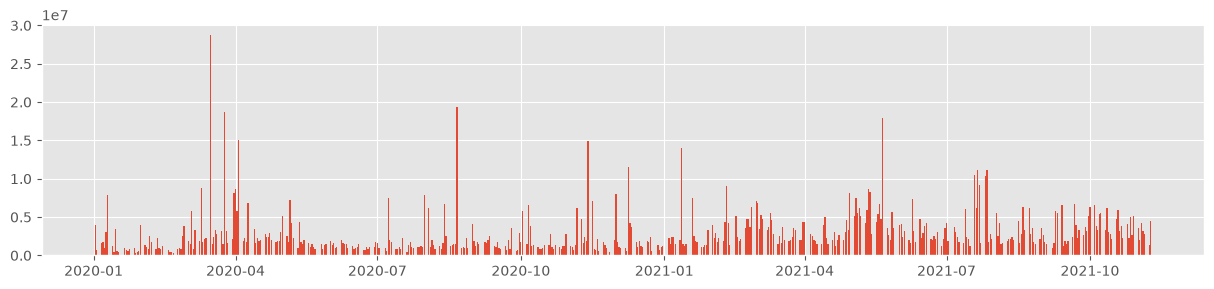

In [14]:
x = df.index
y = df['Volume']
plt.figure(figsize=(15, 3))
plt.bar(x, y)
plt.show()

El gráfico muestra picos grandes de volumen en marzo de 2020, cuando el mercado reaccionó al inicio de la pandemia: un volumen alto indica mucha actividad de compra y venta.

**Clave:** el volumen se grafica mejor como barras (cada día es una cantidad independiente); el precio, como línea (es una trayectoria continua).

**Referencia:** PDF parte 2, págs. 26–30

## 5. Paso 5 — Precio y volumen juntos con `subplot2grid`

El PDF combina en una misma figura el precio de cierre (parte superior, más grande) y el volumen del mismo periodo (parte inferior, más delgado) con `subplot2grid` de matplotlib:

```python
ax = subplot2grid((nrows, ncols), (row, col), rowspan, colspan)
```

- `(nrows, ncols)`: tamaño de la cuadrícula.
- `(row, col)`: posición inicial del gráfico en la cuadrícula.
- `rowspan`, `colspan`: cuántas filas y columnas ocupa.

En el código del PDF, la cuadrícula es de 4 filas por 4 columnas: el gráfico superior empieza en `(0, 0)` y ocupa 3 filas; el inferior empieza en `(3, 0)` y ocupa 1. `plt.tight_layout()` ajusta los subgráficos para que ocupen al máximo la figura.

**Referencia:** PDF parte 2, págs. 31–34

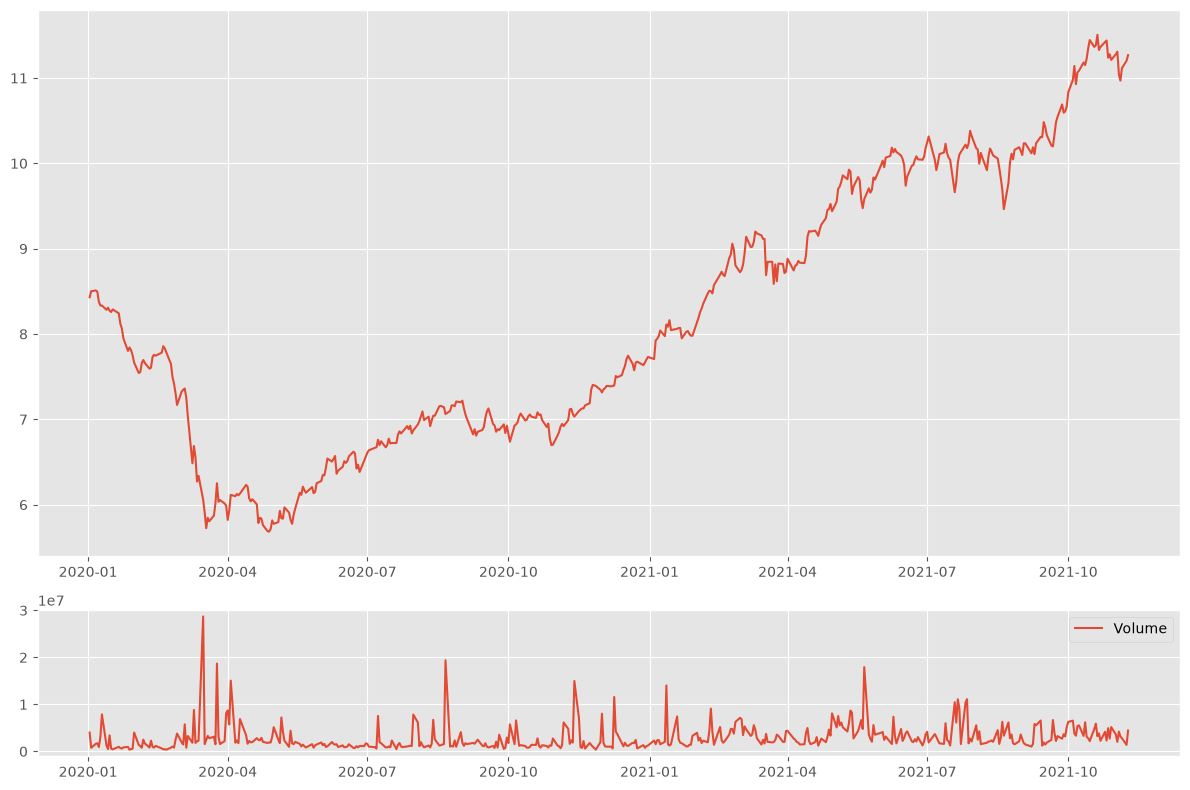

In [15]:
fig = plt.figure(figsize=(12, 8))

top_grid = plt.subplot2grid((4, 4), (0, 0), rowspan=3, colspan=4)
bottom_grid = plt.subplot2grid((4, 4), (3, 0), rowspan=1, colspan=4)

top_grid.plot(df.index, df['Close'], label='Close')
bottom_grid.plot(df.index, df['Volume'], label='Volume')

plt.tight_layout()

plt.legend()
plt.show()

**Nota sobre el PDF:** en el código del PDF, `plt.legend()` solo muestra la leyenda del último gráfico creado (el de volumen); por eso en la imagen del PDF la leyenda `Volume` aparece abajo y el de precios no tiene leyenda. Para que ambos la tengan se llama a `legend()` en cada eje. Además, el PDF repite aquí las líneas de `ticker`, `start` y `end` del paso anterior.

**Ampliación (no está en el PDF):** la misma figura, con leyenda en ambos ejes y el eje horizontal compartido.

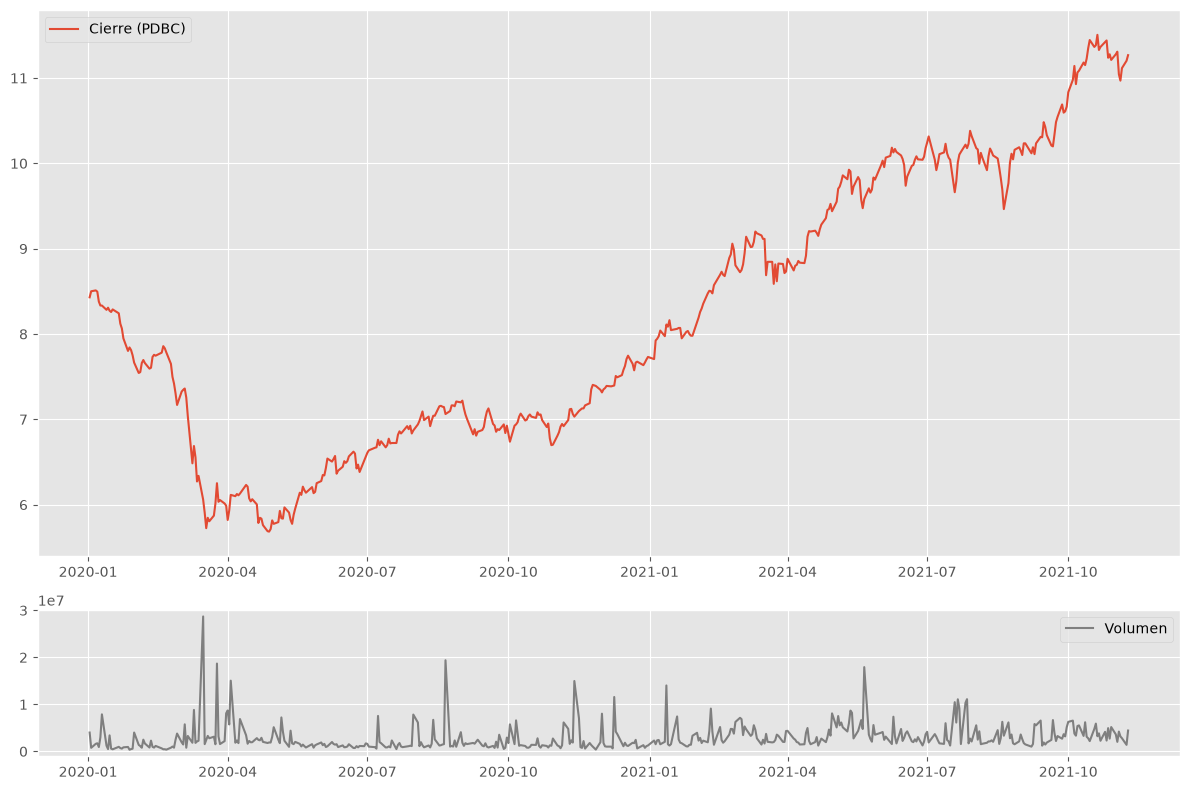

In [16]:
fig = plt.figure(figsize=(12, 8))
top_grid = plt.subplot2grid((4, 4), (0, 0), rowspan=3, colspan=4)
bottom_grid = plt.subplot2grid((4, 4), (3, 0), rowspan=1, colspan=4, sharex=top_grid)

top_grid.plot(df.index, df['Close'], label='Cierre (PDBC)')
bottom_grid.plot(df.index, df['Volume'], label='Volumen', color='tab:gray')

top_grid.legend()
bottom_grid.legend()
plt.tight_layout()
plt.show()

**Clave:** `subplot2grid` permite dividir la figura en una cuadrícula y asignar a cada gráfico un tamaño distinto; es útil para combinar un gráfico principal con otro de apoyo.

**Error común:** llamar `plt.legend()` una sola vez al final: solo afecta al eje activo.

**Referencia:** PDF parte 2, págs. 31–34

## 6. Paso 6 — Cambio porcentual diario con `shift()`

Comparar el dato actual con el de un momento anterior para calcular el cambio porcentual es una tarea común en el trabajo diario. En Excel se resuelve con una fórmula entre dos celdas vecinas; en pandas, `Series.shift()` sirve para alinear cada valor con el del día anterior.

La fórmula del cambio porcentual diario basada en el precio de cierre es:

> Cambio porcentual diario = (Precio de cierre de hoy - Precio de cierre de ayer) / Precio de cierre de ayer * 100

o, en general, `(valor nuevo - valor original) / valor original * 100`.

**Referencia:** PDF parte 2, págs. 35–36

In [17]:
stock.head()

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Date,,,,,,,
2020-01-02,295.3918,57.8005,71.8010,14.5602,111.5526,8.4301,29.22
2020-01-03,293.1551,57.2235,71.1515,14.3926,113.2705,8.5010,29.62
2020-01-06,294.2734,57.5765,71.4148,14.4279,112.6273,8.5112,29.92
2020-01-07,293.4460,57.5984,71.1954,14.4632,112.0736,8.4960,30.04
2020-01-08,295.0100,58.1730,71.4850,14.3926,111.3327,8.3795,29.82


In [18]:
# Serie de cierre de SPY
stock['SPY']

Date
2020-01-02    295.3918
2020-01-03    293.1551
2020-01-06    294.2734
2020-01-07    293.4460
2020-01-08    295.0100
                ...   
2021-11-03    434.6537
2021-11-04    436.7021
2021-11-05    438.2173
2021-11-08    438.5914
2021-11-09    437.1417
Name: SPY, Length: 469, dtype: float64

In [19]:
# Desplaza un día: cada fecha pasa a mostrar el cierre del día anterior
stock['SPY'].shift(1)

Date
2020-01-02         NaN
2020-01-03    295.3918
2020-01-06    293.1551
2020-01-07    294.2734
2020-01-08    293.4460
                ...   
2021-11-03    432.0162
2021-11-04    434.6537
2021-11-05    436.7021
2021-11-08    438.2173
2021-11-09    438.5914
Name: SPY, Length: 469, dtype: float64

`shift(1)` mueve los valores una posición hacia abajo: el primer día queda en `NaN` (no existe un día anterior) y el resto muestra el cierre del día anterior. Dividiendo el cierre de hoy entre el cierre desplazado se obtiene el cambio relativo.

**Nota sobre el PDF:** el PDF llama a la variable `spy_dayily_pc` (con la errata "dayily", por *daily*). Se conserva el identificador del PDF para que el código sea reconocible. Las variables siguientes (`stock_dayily_pc`, `stock_d_cr`) también conservan el nombre del PDF.

In [20]:
spy_dayily_pc = (stock['SPY'] / stock['SPY'].shift(1) - 1) * 100
spy_dayily_pc

Date
2020-01-02         NaN
2020-01-03   -0.757198
2020-01-06    0.381470
2020-01-07   -0.281167
2020-01-08    0.532977
                ...   
2021-11-03    0.610510
2021-11-04    0.471272
2021-11-05    0.346964
2021-11-08    0.085369
2021-11-09   -0.330535
Name: SPY, Length: 469, dtype: float64

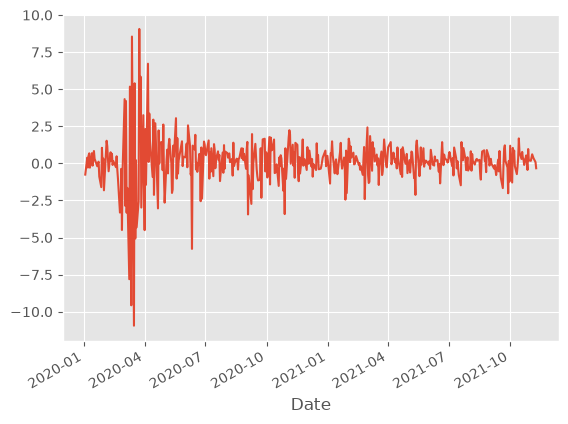

In [21]:
spy_dayily_pc.plot()
plt.show()

La gráfica del cambio porcentual diario de `SPY` muestra una agitación mucho mayor entre marzo y abril de 2020, con oscilaciones diarias de hasta alrededor de 10 %, y luego se tranquiliza. Ese cambio de intensidad es, justamente, la **volatilidad**, que se calcula en el Paso 9.

**Referencia:** PDF parte 2, págs. 37–41

### Histograma del cambio porcentual diario

Un **histograma** muestra la distribución de frecuencias: cuántas veces aparecen los valores en cada tramo. El número de tramos se fija con el parámetro `bins` de `hist()` (por defecto 10); la forma del gráfico cambia con `bins`, por lo que hay que elegirlo observando las características de los datos.

El PDF escribe otra fórmula equivalente, solo para ayudar a entender: `(precio - precio.shift(1)) / precio.shift(1) * 100`. Además, como el primer valor es un dato faltante (`NaN`), lo reemplaza por 0 antes de graficar:

```python
spy_dayily_pc = (stock['SPY'] - stock['SPY'].shift(1)) / stock['SPY'].shift(1) * 100
spy_dayily_pc.iloc[0] = 0
plt.hist(spy_dayily_pc, bins=50)
plt.show()
```

Con 50 tramos, el cambio porcentual diario se divide en 50 intervalos y la altura de cada barra es la frecuencia.

**Referencia:** PDF parte 2, págs. 42–44

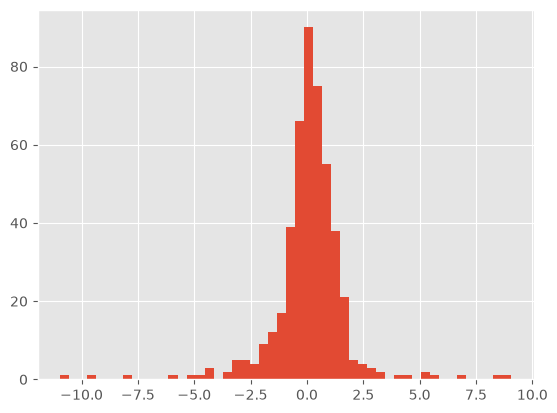

In [22]:
# Fórmula equivalente (solo para entender): mismo resultado que la anterior
spy_dayily_pc = (stock['SPY'] - stock['SPY'].shift(1)) / stock['SPY'].shift(1) * 100

# El primer valor es un dato faltante (NaN): se reemplaza por 0
spy_dayily_pc.iloc[0] = 0

plt.hist(spy_dayily_pc, bins=50)
plt.show()

**Ampliación (no está en el PDF):** pandas ya trae el método `pct_change()`, que hace exactamente `valor / valor.shift(1) - 1`. Se puede comprobar que coincide con la fórmula manual. Además, el histograma permite resumir la distribución con la media y la desviación estándar.

In [23]:
con_pct_change = stock['SPY'].pct_change() * 100
con_pct_change.iloc[0] = 0

print("pct_change() coincide con la fórmula manual:", np.allclose(con_pct_change, spy_dayily_pc))
print("Cambio diario medio de SPY: %.3f %%" % spy_dayily_pc.mean())
print("Desviación estándar: %.3f %%" % spy_dayily_pc.std())
print("Peor día: %.2f %% el %s" % (spy_dayily_pc.min(), spy_dayily_pc.idxmin().date()))

pct_change() coincide con la fórmula manual: True
Cambio diario medio de SPY: 0.097 %
Desviación estándar: 1.632 %
Peor día: -10.94 % el 2020-03-16


**Clave:** `shift(1)` desplaza la serie un día; `(hoy / ayer - 1) * 100` es el cambio porcentual diario. El primer día queda en `NaN` porque no hay día anterior.

**Error común:** dividir sin desplazar, o desplazar en sentido contrario (`shift(-1)` compara con el día siguiente).

**Para el quiz:** un histograma con `bins=50` divide el rango de datos en 50 tramos; el valor por defecto de `bins` es 10.

**Referencia:** PDF parte 2, págs. 35–44

## 7. Paso 7 — Cambio diario de todos los tickers y rendimiento acumulado

Se crea un marco de datos con las variaciones diarias de **todos** los tickers a la vez: pandas aplica la operación columna por columna, alineando por fecha.

```python
stock_dayily_pc = (stock - stock.shift(1)) / stock.shift(1) * 100
stock_dayily_pc.head()
```

**Referencia:** PDF parte 2, pág. 45

In [24]:
stock_dayily_pc = (stock - stock.shift(1)) / stock.shift(1) * 100
stock_dayily_pc.head()

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Date,,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.757198,-0.998261,-0.904584,-1.151083,1.539991,0.841034,1.368925
2020-01-06,0.381470,0.616879,0.370055,0.245265,-0.567844,0.119986,1.012829
2020-01-07,-0.281167,0.038036,-0.307219,0.244665,-0.491621,-0.178588,0.401070
2020-01-08,0.532977,0.997597,0.406768,-0.488135,-0.661083,-1.371234,-0.732357


Después el PDF calcula el **rendimiento acumulado diario simple** sumando la variación diaria de cada día con las anteriores, mediante `.cumsum()`:

```python
stock_d_cr = stock_dayily_pc.cumsum()
```

y lo grafica con `stock_d_cr.plot(figsize=(20, 10))`.

**Referencia:** PDF parte 2, págs. 46–48

In [25]:
stock_d_cr = stock_dayily_pc.cumsum()
stock_d_cr.tail()

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Date,,,,,,,
2021-11-03,44.924410,73.782842,37.397315,18.325707,11.887194,30.870293,17.122371
2021-11-04,45.395681,75.357517,37.563270,18.016593,12.938222,30.182199,18.159408
2021-11-05,45.742645,75.586503,37.885381,17.500586,14.433760,31.521428,19.508382
2021-11-08,45.828014,76.184096,38.096426,17.240657,14.246202,32.296893,19.913475
2021-11-09,45.497479,76.184096,37.821725,17.969413,15.548029,32.884283,20.403388


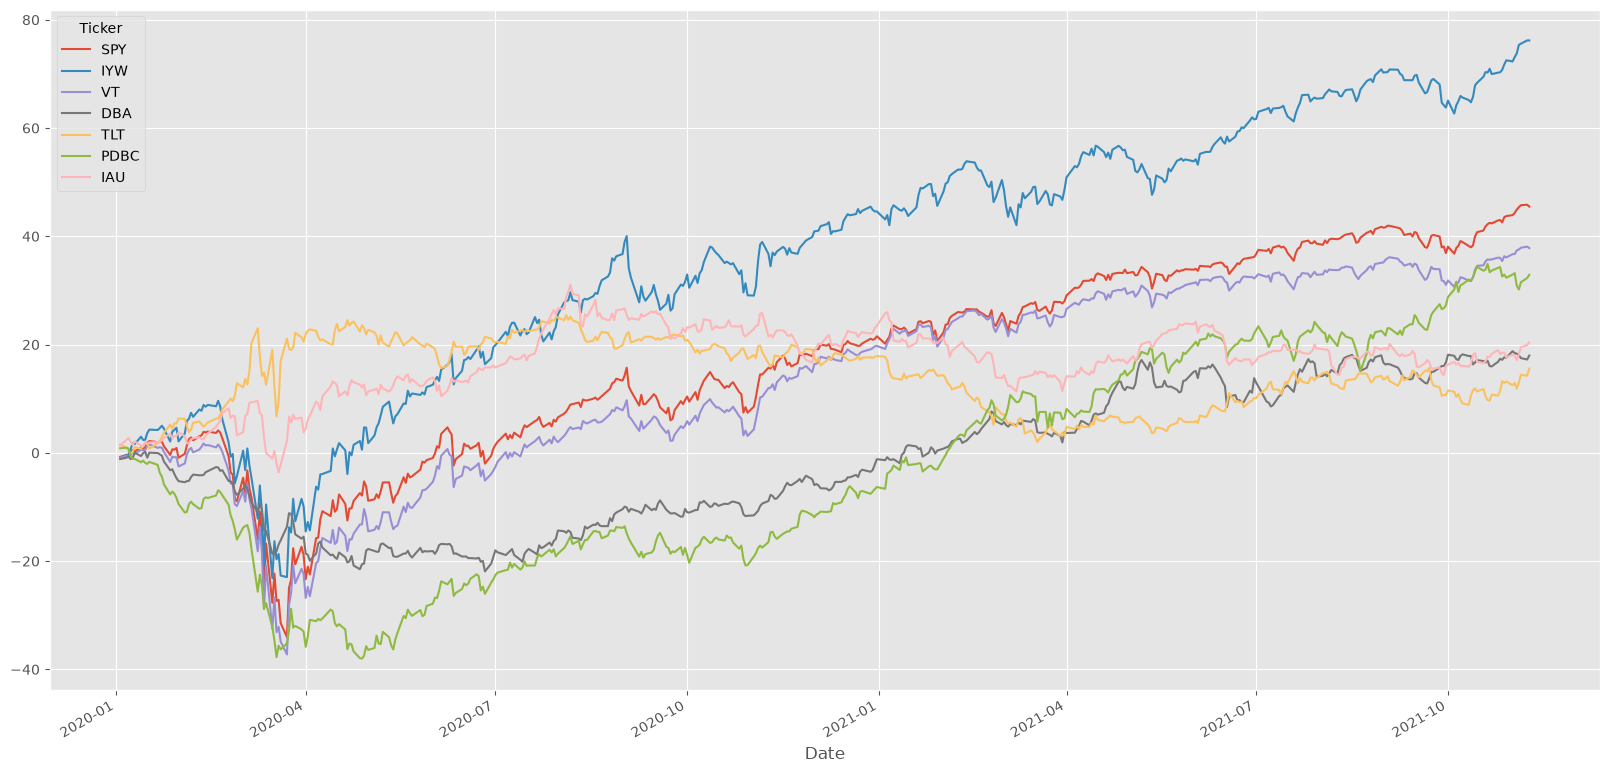

In [26]:
stock_d_cr.plot(figsize=(20, 10))
plt.show()

**Nota sobre el PDF:** el texto de la pág. 46 dice "acumulando y multiplicando" la variación diaria, pero el código usa `.cumsum()`, que **suma**. Sumar los cambios porcentuales diarios da un rendimiento acumulado **simple** (aproximado): no equivale al rendimiento real compuesto, porque cada día se aplica sobre un precio distinto. Por ejemplo, +10 % y luego +10 % es +21 % real, no +20 %. La forma del PDF es válida como indicador simple; la forma exacta se muestra a continuación.

Además, en la imagen del PDF aparece un pico anormal en `IAU` hacia mayo de 2021 (el cambio llega a casi 120). Es probablemente un defecto de los datos de esa descarga (inferencia: un salto de precio mal registrado, por ejemplo una división de acciones sin ajustar). Con los datos actuales ese pico no existe, por eso `IAU` aparece aquí con una curva limpia y más cercana al comportamiento real del oro.

**Ampliación (no está en el PDF):** rendimiento acumulado compuesto, con `(1 + r).cumprod() - 1`.

In [27]:
# Rendimiento acumulado compuesto (exacto) en porcentaje
r = stock_dayily_pc.fillna(0) / 100
stock_cr_compuesto = ((1 + r).cumprod() - 1) * 100

comparacion = pd.DataFrame({
    "Simple (cumsum)": stock_d_cr.iloc[-1],
    "Compuesto (cumprod)": stock_cr_compuesto.iloc[-1],
}).round(2)
comparacion

,Simple (cumsum),Compuesto (cumprod)
Ticker,,
SPY,45.50,47.99
IYW,76.18,94.87
VT,37.82,37.37
DBA,17.97,17.33
TLT,15.55,13.28
PDBC,32.88,33.66
IAU,20.40,19.34


In [28]:
# Comprobación: el rendimiento compuesto es la variación entre el primer y el último cierre
total_spy = (stock['SPY'].iloc[-1] / stock['SPY'].iloc[0] - 1) * 100
print("SPY, variación total del periodo: %.2f %%" % total_spy)
print("SPY, acumulado compuesto:         %.2f %%" % stock_cr_compuesto['SPY'].iloc[-1])

SPY, variación total del periodo: 47.99 %
SPY, acumulado compuesto:         47.99 %


**Ampliación (no está en el PDF):** el PDF menciona en su lista de tareas (pág. 7) el rendimiento por periodos mensuales y la media móvil, aunque no los desarrolla en las diapositivas. Se muestran como complemento: el rendimiento mensual con `resample` y la media móvil con `rolling().mean()`.

Ticker        SPY    IYW     VT   DBA   TLT   PDBC   IAU
Date                                                    
2020-01-31    NaN    NaN    NaN   NaN   NaN    NaN   NaN
2020-02-29  -7.92  -6.60  -7.22 -2.56  6.63  -6.48 -0.66
2020-03-31 -12.49  -9.32 -14.76 -7.74  6.38 -16.47  0.00
2020-04-30  12.70  14.62  10.37 -2.70  1.22  -2.88  6.90
2020-05-31   4.76   7.53   5.21 -0.22 -1.76   7.49  2.61
2020-06-30   1.77   7.28   3.07 -1.10  0.34   4.86  2.78


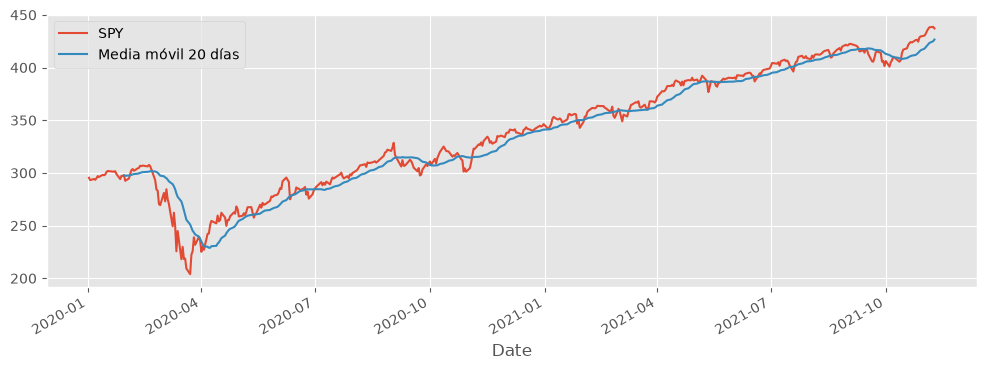

In [29]:
# Rendimiento mensual de cada ticker, en porcentaje (último cierre de cada mes frente al mes anterior)
mensual = stock.resample('ME').last().pct_change() * 100
print(mensual.round(2).head(6))

# Media móvil de 20 días de SPY frente al cierre diario
media_movil_20 = stock['SPY'].rolling(window=20).mean()
pd.DataFrame({'SPY': stock['SPY'], 'Media móvil 20 días': media_movil_20}).plot(figsize=(12, 4))
plt.show()

**Clave:** `.cumsum()` acumula la suma de los cambios diarios (rendimiento acumulado simple); `(1 + r).cumprod() - 1` da el rendimiento compuesto exacto.

**Error común:** creer que sumar porcentajes diarios da el rendimiento real; solo lo aproxima, y la diferencia crece cuando hay cambios grandes.

**Referencia:** PDF parte 2, págs. 45–48

## 8. Paso 8 — Correlación entre activos y mapa de calor

El **coeficiente de correlación** mide la fuerza de la asociación entre dos series. Cuanto más cerca de 1,0 es el valor, más fuerte es la relación; cuanto más cerca de 0, menos relación. Un valor negativo indica que se mueven en sentidos opuestos. Se calcula con `.corr()` sobre las variaciones diarias:

```python
df_corr = stock_dayily_pc.corr()
```

**Referencia:** PDF parte 2, pág. 49

In [30]:
df_corr = stock_dayily_pc.corr()
df_corr

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Ticker,,,,,,,
SPY,1.000000,0.920048,0.981413,0.334650,-0.401104,0.466579,0.158061
IYW,0.920048,1.000000,0.893215,0.295104,-0.294952,0.375512,0.195905
VT,0.981413,0.893215,1.000000,0.359151,-0.396820,0.495601,0.183728
DBA,0.334650,0.295104,0.359151,1.000000,-0.218171,0.545567,0.153888
TLT,-0.401104,-0.294952,-0.396820,-0.218171,1.000000,-0.253262,0.203333
PDBC,0.466579,0.375512,0.495601,0.545567,-0.253262,1.000000,0.203859
IAU,0.158061,0.195905,0.183728,0.153888,0.203333,0.203859,1.000000


Se lee así: la diagonal es siempre 1 (cada activo con sí mismo); `SPY`, `IYW` y `VT` tienen entre sí una correlación muy alta (alrededor de 0,9 o más): son acciones y se mueven juntas. `TLT` (bonos) tiene correlación negativa con las acciones (alrededor de -0,4).

**Nota sobre el PDF:** el PDF muestra `IAU` con una correlación casi nula (alrededor de 0,02) con todos los demás. Eso se debe en parte al pico erróneo de datos que se comentó en el Paso 7. Con los datos actuales y sin ese pico, `IAU` muestra una correlación positiva pequeña (alrededor de 0,15 a 0,20): sigue siendo débil, pero no nula. El resto de la tabla coincide con el PDF con diferencias de milésimas.

**Referencia:** PDF parte 2, pág. 49

### Mapa de calor

El PDF visualiza la matriz de correlación como mapa de calor con `plt.imshow`. Con el mapa de colores `'hot'`, cuanto más oscuro es el color menor es la correlación, y cuanto más brillante, mayor es.

```python
plt.imshow(df_corr, cmap='hot', interpolation='none')
plt.colorbar()
plt.xticks(range(len(df_corr)), df_corr.columns)
plt.yticks(range(len(df_corr)), df_corr.columns)
plt.gcf().set_size_inches(10, 10)
```

- `imshow` pinta cada celda de la matriz con un color según su valor.
- `colorbar` agrega la escala de colores.
- `xticks` / `yticks` reemplazan los números de posición por los nombres de los tickers.

**Referencia:** PDF parte 2, págs. 50–51

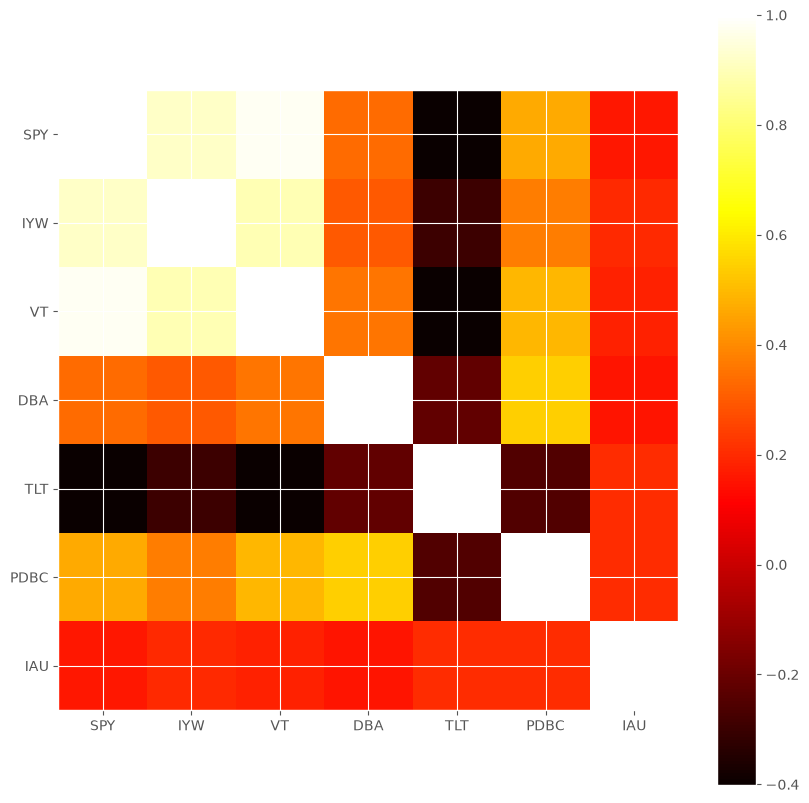

In [31]:
plt.imshow(df_corr, cmap ='hot', interpolation ='none')
plt.colorbar()
plt.xticks(range(len(df_corr)), df_corr.columns)
plt.yticks(range(len(df_corr)), df_corr.columns)

plt.gcf().set_size_inches(10, 10)
plt.show()

**Ampliación (no está en el PDF):** el mismo mapa con `seaborn`, que muestra el valor en cada celda y fija la escala entre -1 y 1, lo que facilita la lectura.

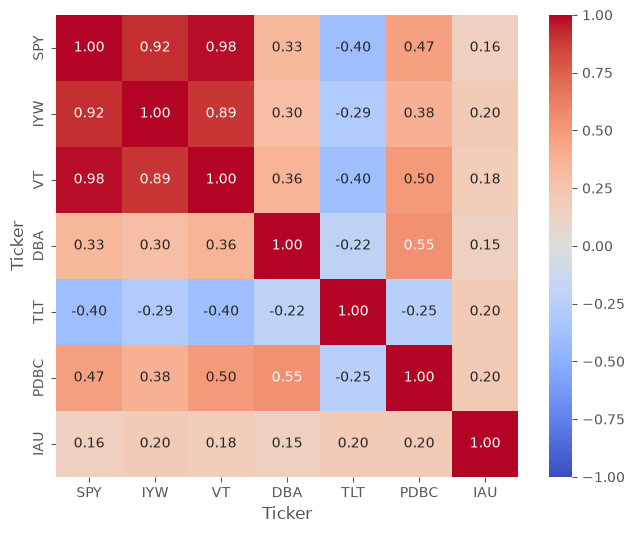

In [32]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.show()

### Diagrama de dispersión de la correlación

El PDF también dibuja un diagrama de dispersión con las columnas `SPY` y `VT` **de la matriz de correlación**:

```python
plt.scatter(df_corr.SPY, df_corr.VT)
plt.show()
```

**Referencia:** PDF parte 2, pág. 52

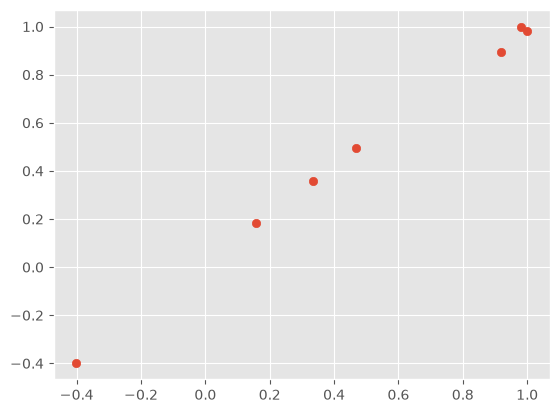

In [33]:
plt.scatter(df_corr.SPY, df_corr.VT)
plt.show()

**Nota sobre el PDF:** cada punto del gráfico anterior corresponde a un ticker, y sus coordenadas son la correlación de ese ticker con `SPY` (eje horizontal) y con `VT` (eje vertical). Los puntos se alinean porque `SPY` y `VT` se parecen mucho entre sí. No es un diagrama de dispersión de los **cambios diarios**; para ver la relación real entre los dos activos hay que dibujar directamente sus cambios diarios, como se hace abajo (ampliación).

**Ampliación (no está en el PDF):** dispersión de los cambios diarios de `SPY` frente a los de `VT` y de `SPY` frente a los de `TLT`.

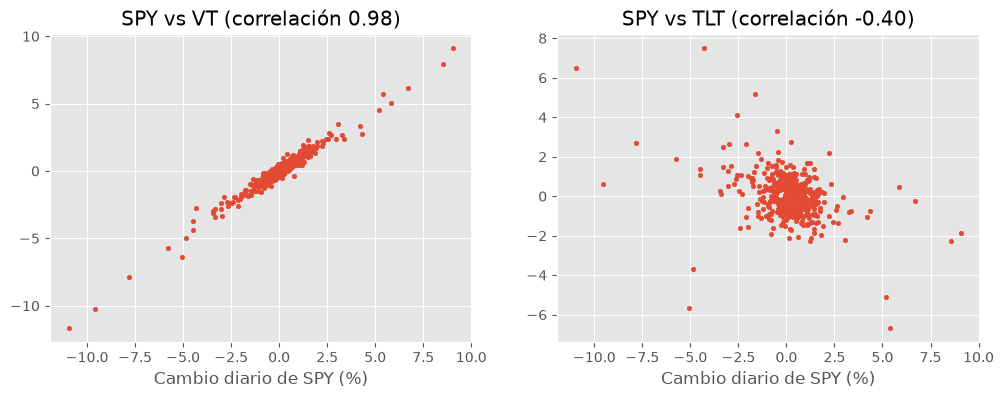

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(stock_dayily_pc['SPY'], stock_dayily_pc['VT'], s=10)
axs[0].set_title("SPY vs VT (correlación %.2f)" % df_corr.loc['SPY', 'VT'])
axs[1].scatter(stock_dayily_pc['SPY'], stock_dayily_pc['TLT'], s=10)
axs[1].set_title("SPY vs TLT (correlación %.2f)" % df_corr.loc['SPY', 'TLT'])
for ax in axs:
    ax.set_xlabel("Cambio diario de SPY (%)")
plt.show()

### Cómo interpretar la correlación

El PDF extrae varias conclusiones:

- Los bonos estadounidenses y las acciones están casi completamente descorrelacionados, o incluso inversamente correlacionados, según las condiciones económicas: cuando la economía va bien, las empresas mejoran y las acciones suben; cuando va mal, el valor de los bonos sube. Ahora se puede comprobar con datos reales y no solo con teoría.
- Cada activo tiene un efecto complementario con los demás, y con eso se puede construir una estrategia para mitigar el riesgo.
- Un coeficiente cercano a 1 significa que los valores suben y bajan juntos: no hay efecto de mitigación del riesgo entre ellos. Un coeficiente cercano a 0 indica que no hay relación entre sus movimientos y que el efecto de mitigación del riesgo es grande.
- Fuera de las finanzas puede servir para decisiones basadas en datos: relación entre momento de las ventas y ventas por producto, fecha de lanzamiento de un producto, composición de carteras de empresas.

**Ampliación (no está en el PDF):** la correlación cambia con el contexto. Se compara la del periodo de la pandemia con la del resto del tiempo.

In [35]:
# Correlación de los cambios diarios solo durante la crisis de COVID-19 y fuera de ella
en_crisis = stock_dayily_pc['2020-02-01':'2020-07-31']
fuera = pd.concat([stock_dayily_pc[:'2020-01-31'], stock_dayily_pc['2020-08-01':]])

print("Correlación SPY-TLT en la crisis:", round(en_crisis['SPY'].corr(en_crisis['TLT']), 3))
print("Correlación SPY-TLT fuera de ella:", round(fuera['SPY'].corr(fuera['TLT']), 3))
print("Correlación SPY-VT en la crisis:", round(en_crisis['SPY'].corr(en_crisis['VT']), 3))
print("Correlación SPY-VT fuera de ella:", round(fuera['SPY'].corr(fuera['VT']), 3))

Correlación SPY-TLT en la crisis: -0.519
Correlación SPY-TLT fuera de ella: -0.124
Correlación SPY-VT en la crisis: 0.988
Correlación SPY-VT fuera de ella: 0.958


**Clave:** `.corr()` calcula la matriz de correlación entre todas las columnas. Se aplica sobre los **cambios diarios** y no sobre los precios, porque dos precios que solo suben con el tiempo parecen correlacionados aunque no tengan relación real.

**Error común:** confundir correlación con causalidad: que dos activos se muevan juntos no significa que uno cause al otro.

**Para el quiz:** correlación cercana a 1 = se mueven juntos (sin mitigación de riesgo); cercana a 0 = sin relación (mayor mitigación); negativa = se mueven en sentidos opuestos.

**Referencia:** PDF parte 2, págs. 49–53

## 9. Paso 9 — Volatilidad con una ventana móvil

La **volatilidad** mide cuánto varía el precio de un activo en un periodo. Se usa para estimar el riesgo: se compara la volatilidad de un valor con la de un dato de referencia estable (por ejemplo, el índice completo del mercado).

Según el PDF, la volatilidad se obtiene calculando la **desviación estándar** de la variación diaria con una **media móvil** (ventana deslizante). Lo que más influye es el tamaño de la ventana:

- Si la ventana es amplia, el resultado se vuelve borroso y poco representativo del momento.
- Si es demasiado estrecha, se acerca a la desviación estándar de cada día y pierde sentido.

Fijar el tamaño de la ventana es difícil e importante, y no todo se resuelve con un cálculo: hay que decidir comprendiendo el contexto y el resultado que se quiere lograr. Los resultados pueden cambiar según el criterio de quien analiza, y eso puede cambiar la decisión en el mundo real.

```python
periods = 75
vol = stock_dayily_pc.rolling(window=periods).std()
vol
```

**Referencia:** PDF parte 2, págs. 54–55

In [36]:
periods = 75

vol = stock_dayily_pc.rolling(window=periods).std()

vol

Ticker,SPY,IYW,VT,DBA,TLT,PDBC,IAU
Date,,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2021-11-03,0.676565,0.935394,0.652157,0.786173,0.819785,1.149871,0.816876
2021-11-04,0.672933,0.944225,0.642867,0.768887,0.816211,1.127112,0.824916
2021-11-05,0.673416,0.940789,0.643522,0.764072,0.827213,1.132205,0.839324


Las primeras 75 filas son `NaN` porque una ventana de 75 días necesita 75 datos para calcular su primera desviación estándar (en este conjunto, la primera fila es `NaN` en el cambio diario, por lo que la primera volatilidad llega con la fila 76). El PDF grafica la volatilidad de `SPY`, `TLT` y `DBA`:

```python
vol["SPY"].plot()
vol["TLT"].plot()
vol["DBA"].plot()
```

**Referencia:** PDF parte 2, págs. 55–56

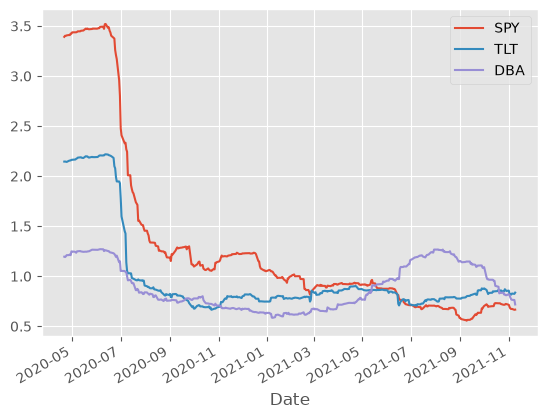

In [37]:
vol["SPY"].plot()
vol["TLT"].plot()
vol["DBA"].plot()
plt.legend()
plt.show()

**Nota sobre el PDF:** el gráfico del PDF no incluye leyenda ni etiquetas, por lo que no se sabe qué curva es cada ticker; aquí se agregó `plt.legend()` (las series ya llevan el nombre del ticker). La volatilidad es alta al comienzo de la ventana porque incluye marzo de 2020 y cae a partir de mediados de 2020 cuando esa crisis sale de la ventana.

**Ampliación (no está en el PDF):** efecto del tamaño de la ventana sobre la volatilidad de `SPY`. Con una ventana corta la curva reacciona rápido y es ruidosa; con una larga es más suave pero tarda más en reflejar los cambios.

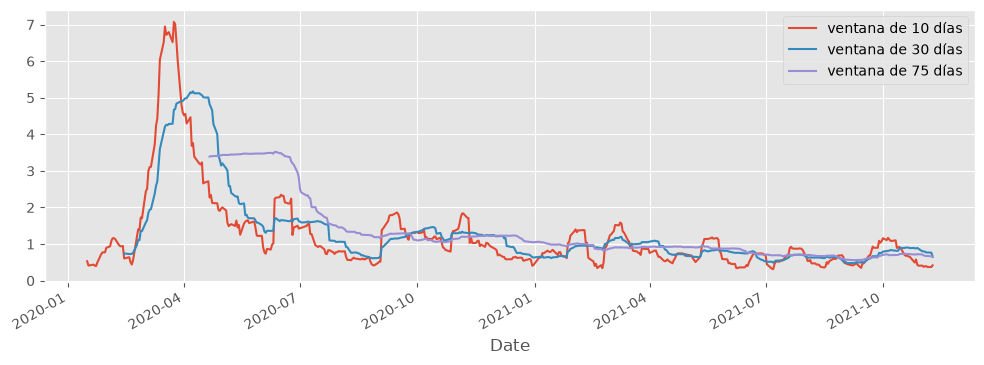

In [38]:
fig, ax = plt.subplots(figsize=(12, 4))
for ventana in (10, 30, 75):
    stock_dayily_pc['SPY'].rolling(window=ventana).std().plot(ax=ax, label=f"ventana de {ventana} días")
ax.legend()
plt.show()

In [39]:
# Volatilidad al final del periodo y volatilidad promedio de cada ticker (ventana de 75 días)
resumen = pd.DataFrame({
    "Volatilidad final": vol.iloc[-1],
    "Volatilidad media": vol.mean(),
    "Volatilidad del periodo completo": stock_dayily_pc.std(),
}).round(3)
resumen.sort_values("Volatilidad del periodo completo")

,Volatilidad final,Volatilidad media,Volatilidad del periodo completo
Ticker,,,
DBA,0.718,0.899,0.920
IAU,0.841,1.062,1.078
TLT,0.836,0.990,1.150
PDBC,1.133,1.220,1.281
VT,0.641,1.274,1.600
SPY,0.666,1.305,1.633
IYW,0.930,1.744,2.001


**Clave:** `rolling(window=n).std()` calcula la desviación estándar de las últimas `n` observaciones en cada fecha; es la forma de medir la volatilidad a lo largo del tiempo.

**Error común:** elegir una ventana sin pensar en el objetivo; una ventana muy larga oculta los cambios recientes y una muy corta es casi ruido.

**Para el quiz:** el PDF usa `periods = 75` y `rolling(window=periods).std()`; las primeras filas son `NaN`.

**Referencia:** PDF parte 2, págs. 54–56

## Proyecto de la unidad

**Problema:** analizar con datos reales cómo se comportan distintos activos del mercado estadounidense (acciones, bonos, materias primas y oro) entre 2020 y 2021: precios, volumen, variación diaria, rendimiento acumulado, correlación y volatilidad.

**Plan de programación (los nueve pasos del PDF):**

1. Preparar la adquisición: instalar la biblioteca y escribir la función `get_stock_data(ticker, start, end)`.
2. Crear un marco de datos por ticker, pivotarlos por `Ticker`/`Close` y unirlos con `concat(axis=1)`.
3. Graficar los precios de cierre y aislar el periodo de COVID-19 con un corte por fechas.
4. Graficar el volumen de negociación de un ticker en barras.
5. Combinar precio y volumen con `subplot2grid`.
6. Calcular el cambio porcentual diario con `shift()` y graficar su distribución (histograma).
7. Calcular los cambios de todos los tickers y su rendimiento acumulado.
8. Calcular y visualizar la correlación entre activos.
9. Calcular la volatilidad con una ventana móvil.

A continuación el flujo completo en una sola función, con los datos locales, que devuelve los resultados principales. La descarga en línea queda como código de referencia comentado.

In [40]:
# Para descargar los datos en línea (requiere conexión), este sería el reemplazo de la lectura del CSV:
# tickers = ["SPY", "IYW", "VT", "DBA", "TLT", "PDBC", "IAU"]
# marcos = [yf.Ticker(t).history(start=datetime(2020, 1, 1), end=datetime(2021, 11, 10)) for t in tickers]
# stock = pd.concat([m["Close"].rename(t) for m, t in zip(marcos, tickers)], axis=1)


def analisis_financiero(ruta_csv, inicio_crisis="2020-02-01", fin_crisis="2020-07-31", ventana=75):
    """Ejecuta el análisis completo y devuelve los resultados principales en un diccionario."""
    # Pasos 1 y 2: datos de cierre, un ticker por columna
    stock = pd.read_csv(ruta_csv, index_col="Date", parse_dates=True)

    # Paso 3: periodo de la crisis por corte de fechas
    covid = stock[inicio_crisis:fin_crisis]

    # Paso 6 y 7: cambio porcentual diario de todos los tickers y rendimiento acumulado simple
    cambio_diario = (stock - stock.shift(1)) / stock.shift(1) * 100
    acumulado = cambio_diario.cumsum()

    # Paso 8: correlación entre los cambios diarios
    correlacion = cambio_diario.corr()

    # Paso 9: volatilidad con ventana móvil
    volatilidad = cambio_diario.rolling(window=ventana).std()

    return {
        "stock": stock,
        "covid": covid,
        "cambio_diario": cambio_diario,
        "acumulado": acumulado,
        "correlacion": correlacion,
        "volatilidad": volatilidad,
    }


resultados = analisis_financiero("../datos/u39-cierre.csv")
print("Días analizados:", len(resultados["stock"]))
print("Días de la crisis:", len(resultados["covid"]))

Días analizados: 469
Días de la crisis: 126


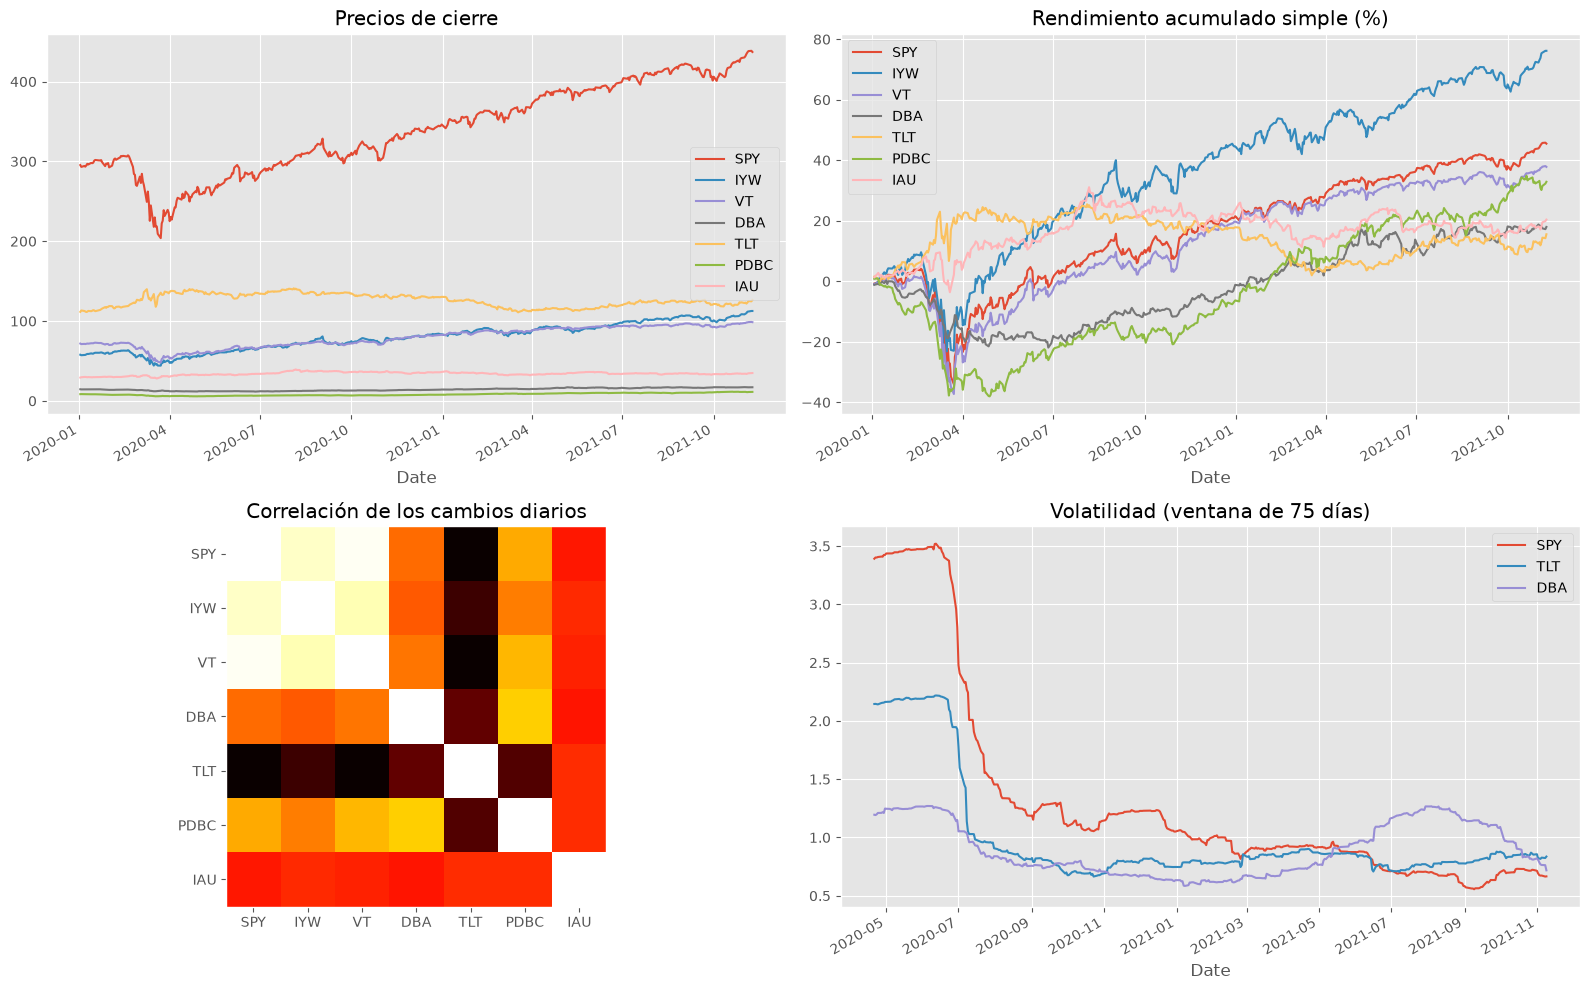

In [41]:
# Resultado esperado: tablas y gráficos de síntesis
stock = resultados["stock"]
cambio_diario = resultados["cambio_diario"]
correlacion = resultados["correlacion"]
volatilidad = resultados["volatilidad"]

fig, axs = plt.subplots(2, 2, figsize=(16, 10))

stock.plot(ax=axs[0, 0], title="Precios de cierre")
resultados["acumulado"].plot(ax=axs[0, 1], title="Rendimiento acumulado simple (%)")
axs[1, 0].imshow(correlacion, cmap="hot", interpolation="none")
axs[1, 0].set_xticks(range(len(correlacion)), correlacion.columns)
axs[1, 0].set_yticks(range(len(correlacion)), correlacion.columns)
axs[1, 0].set_title("Correlación de los cambios diarios")
axs[1, 0].grid(False)
volatilidad[["SPY", "TLT", "DBA"]].plot(ax=axs[1, 1], title="Volatilidad (ventana de 75 días)")

plt.tight_layout()
plt.show()

In [42]:
# Conclusiones numéricas del análisis
total = ((stock.iloc[-1] / stock.iloc[0] - 1) * 100).round(1).sort_values(ascending=False)
print("Variación total del periodo (%):")
print(total)
print()
print("Activo más volátil en todo el periodo:", cambio_diario.std().idxmax())
print("Activo menos volátil en todo el periodo:", cambio_diario.std().idxmin())

# Par de activos con mayor correlación (sin contar la diagonal)
pares = correlacion.where(~np.eye(len(correlacion), dtype=bool)).stack()
print("Par más correlacionado:", pares.idxmax(), round(pares.max(), 3))
print("Par menos correlacionado:", pares.idxmin(), round(pares.min(), 3))

Variación total del periodo (%):
IYW     94.9
SPY     48.0
VT      37.4
PDBC    33.7
IAU     19.3
DBA     17.3
TLT     13.3
dtype: float64

Activo más volátil en todo el periodo: IYW
Activo menos volátil en todo el periodo: DBA
Par más correlacionado: ('SPY', 'VT') 0.981
Par menos correlacionado: ('SPY', 'TLT') -0.401


**Lectura del resultado:**

- Las acciones (`SPY`, `VT`, `IYW`) tienen correlación alta entre sí; `IYW` (tecnología) es el que más rinde en el periodo y también uno de los más volátiles.
- Los bonos (`TLT`) tienen correlación negativa con las acciones: son un activo complementario que reduce el riesgo de una cartera.
- Las materias primas (`DBA`, `PDBC`) y el oro (`IAU`) aportan correlaciones intermedias o bajas, y por eso diversifican.
- La volatilidad de `SPY` y `TLT` fue mucho mayor al comienzo de la pandemia que después.

**Aviso:** este análisis es un ejercicio de aprendizaje con datos históricos de un periodo corto; no es una recomendación de inversión.

**Referencia:** PDF parte 2, págs. 6–56

## Práctica

### Ejercicio 1 — Cambio porcentual entre dos valores

Escribe `cambio_porcentual(hoy, ayer)` que devuelva el cambio porcentual `(hoy - ayer) / ayer * 100`, redondeado a 2 decimales.

In [43]:
def cambio_porcentual(hoy, ayer):
    # Escribe tu solución aquí
    pass

In [44]:
verificar("110 frente a 100", cambio_porcentual(110, 100), 10.0)
verificar("90 frente a 100", cambio_porcentual(90, 100), -10.0)
verificar("50 frente a 40", cambio_porcentual(50, 40), 25.0)

Incorrecto: 110 frente a 100. Se esperaba 10.0 y se obtuvo None
Incorrecto: 90 frente a 100. Se esperaba -10.0 y se obtuvo None
Incorrecto: 50 frente a 40. Se esperaba 25.0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def cambio_porcentual(hoy, ayer):
    return round((hoy - ayer) / ayer * 100, 2)
```

Es la fórmula del PDF (pág. 36): valor nuevo menos valor original, dividido entre el original y por 100.
</details>

### Ejercicio 2 — Cambios diarios con shift

Escribe `cambio_diario(precios)` que reciba una lista de precios y devuelva la lista de cambios porcentuales diarios redondeados a 2 decimales, sin el primer día (que no tiene día anterior). Usa `pd.Series` y `shift(1)`.

In [45]:
def cambio_diario(precios):
    # Escribe tu solución aquí
    pass

In [46]:
verificar("100, 110, 99", cambio_diario([100, 110, 99]), [10.0, -10.0])
verificar("sin cambios", cambio_diario([50, 50]), [0.0])
verificar("200, 100, 150", cambio_diario([200, 100, 150]), [-50.0, 50.0])

Incorrecto: 100, 110, 99. Se esperaba [10.0, -10.0] y se obtuvo None
Incorrecto: sin cambios. Se esperaba [0.0] y se obtuvo None
Incorrecto: 200, 100, 150. Se esperaba [-50.0, 50.0] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def cambio_diario(precios):
    serie = pd.Series(precios, dtype=float)
    cambio = (serie / serie.shift(1) - 1) * 100
    return cambio.dropna().round(2).tolist()
```

`shift(1)` alinea cada precio con el del día anterior; el primer valor es `NaN` y se elimina con `dropna()`.
</details>

### Ejercicio 3 — Acumulado simple y compuesto

Escribe `acumulados(precios)` que devuelva una tupla `(simple, compuesto)` con el rendimiento acumulado final en porcentaje: `simple` es la suma de los cambios diarios (como `cumsum` del PDF) y `compuesto` es la variación entre el primer y el último precio. Redondea a 2 decimales.

In [47]:
def acumulados(precios):
    # Escribe tu solución aquí
    pass

In [48]:
verificar("100, 110, 121", acumulados([100, 110, 121]), (20.0, 21.0))
verificar("100, 120, 60", acumulados([100, 120, 60]), (-30.0, -40.0))
verificar("sin cambios", acumulados([100, 100]), (0.0, 0.0))

Incorrecto: 100, 110, 121. Se esperaba (20.0, 21.0) y se obtuvo None
Incorrecto: 100, 120, 60. Se esperaba (-30.0, -40.0) y se obtuvo None
Incorrecto: sin cambios. Se esperaba (0.0, 0.0) y se obtuvo None


<details><summary>Ver solución</summary>

```python
def acumulados(precios):
    serie = pd.Series(precios, dtype=float)
    cambios = (serie / serie.shift(1) - 1) * 100
    simple = round(cambios.cumsum().iloc[-1], 2)
    compuesto = round((serie.iloc[-1] / serie.iloc[0] - 1) * 100, 2)
    return (float(simple), float(compuesto))
```

Sumar +10 % y +10 % da 20 %, pero el rendimiento real es 21 %. La diferencia crece con los cambios grandes (+20 % y -50 % suma -30 %, pero el real es -40 %).
</details>

### Ejercicio 4 — Media móvil

Escribe `media_movil(precios, ventana)` que devuelva la lista de medias móviles con la ventana indicada, sin los valores `NaN` iniciales. Usa `rolling(window=ventana).mean()`.

In [49]:
def media_movil(precios, ventana):
    # Escribe tu solución aquí
    pass

In [50]:
verificar("ventana 2", media_movil([1, 2, 3, 4, 5], 2), [1.5, 2.5, 3.5, 4.5])
verificar("ventana 3", media_movil([1, 2, 3, 4, 5], 3), [2.0, 3.0, 4.0])
verificar("ventana igual al largo", media_movil([1, 2, 3, 4, 5], 5), [3.0])

Incorrecto: ventana 2. Se esperaba [1.5, 2.5, 3.5, 4.5] y se obtuvo None
Incorrecto: ventana 3. Se esperaba [2.0, 3.0, 4.0] y se obtuvo None
Incorrecto: ventana igual al largo. Se esperaba [3.0] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def media_movil(precios, ventana):
    serie = pd.Series(precios, dtype=float)
    return serie.rolling(window=ventana).mean().dropna().tolist()
```

Una ventana de `n` necesita `n` datos, así que las primeras `n - 1` posiciones son `NaN` y se descartan.
</details>

### Ejercicio 5 — Volatilidad de la última ventana

Escribe `volatilidad(cambios, ventana)` que reciba una lista de cambios diarios y devuelva la desviación estándar (la de `rolling(...).std()`, con `ddof=1`) de la última ventana, redondeada a 4 decimales.

In [51]:
def volatilidad(cambios, ventana):
    # Escribe tu solución aquí
    pass

In [52]:
verificar("alterna +1 y -1", volatilidad([1, -1, 1, -1], 2), 1.4142)
verificar("valores iguales", volatilidad([2, 2, 2], 3), 0.0)
verificar("1, 2, 3", volatilidad([1, 2, 3], 3), 1.0)

Incorrecto: alterna +1 y -1. Se esperaba 1.4142 y se obtuvo None
Incorrecto: valores iguales. Se esperaba 0.0 y se obtuvo None
Incorrecto: 1, 2, 3. Se esperaba 1.0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def volatilidad(cambios, ventana):
    serie = pd.Series(cambios, dtype=float)
    return round(float(serie.rolling(window=ventana).std().iloc[-1]), 4)
```

`rolling(window=ventana).std()` calcula la desviación estándar de cada ventana; la última fila corresponde a los datos más recientes.
</details>

### Ejercicio 6 — Par de activos más correlacionado

Escribe `par_mas_correlacionado(datos)` que reciba un `DataFrame` de cambios diarios y devuelva una tupla con los nombres del par de columnas (en el orden en que aparecen) con mayor correlación, sin contar la diagonal.

In [53]:
def par_mas_correlacionado(datos):
    # Escribe tu solución aquí
    pass

In [54]:
a = pd.DataFrame({"A": [1, 2, 3, 4], "B": [2, 4, 6, 8], "C": [4, 3, 2, 1]})
b = pd.DataFrame({"X": [1, 2, 3, 4], "Y": [4, 3, 2, 1.5], "Z": [1, 2, 4, 3]})
verificar("A y B perfectamente correlacionados", par_mas_correlacionado(a), ("A", "B"))
verificar("X y Z", par_mas_correlacionado(b), ("X", "Z"))

Incorrecto: A y B perfectamente correlacionados. Se esperaba ('A', 'B') y se obtuvo None
Incorrecto: X y Z. Se esperaba ('X', 'Z') y se obtuvo None


<details><summary>Ver solución</summary>

```python
def par_mas_correlacionado(datos):
    corr = datos.corr()
    pares = corr.where(~np.eye(len(corr), dtype=bool)).stack()
    return tuple(pares.idxmax())
```

La diagonal vale siempre 1: se enmascara con `np.eye`. `stack()` convierte la matriz en una serie con pares como índice, y `idxmax()` devuelve el par de mayor valor; en una matriz simétrica el primer par encontrado respeta el orden de las columnas.
</details>

### Ejercicio 7 — Clasificar el riesgo frente a una referencia

El PDF compara la volatilidad de un valor con la de un dato de referencia estable. Escribe `clasificar_riesgo(vol_activo, vol_referencia)` que devuelva `'mayor riesgo'` si la volatilidad del activo supera en más de un 10 % a la de la referencia, `'menor riesgo'` si es inferior a un 90 % de ella, y `'riesgo similar'` en los demás casos.

In [55]:
def clasificar_riesgo(vol_activo, vol_referencia):
    # Escribe tu solución aquí
    pass

In [56]:
verificar("el doble", clasificar_riesgo(2.0, 1.0), "mayor riesgo")
verificar("la mitad", clasificar_riesgo(0.5, 1.0), "menor riesgo")
verificar("casi igual", clasificar_riesgo(1.05, 1.0), "riesgo similar")

Incorrecto: el doble. Se esperaba 'mayor riesgo' y se obtuvo None
Incorrecto: la mitad. Se esperaba 'menor riesgo' y se obtuvo None
Incorrecto: casi igual. Se esperaba 'riesgo similar' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def clasificar_riesgo(vol_activo, vol_referencia):
    razon = vol_activo / vol_referencia
    if razon > 1.1:
        return 'mayor riesgo'
    if razon < 0.9:
        return 'menor riesgo'
    return 'riesgo similar'
```

Se compara la razón entre ambas volatilidades con los umbrales 1,1 y 0,9. El criterio es una decisión de análisis (el PDF insiste en que el juicio de quien analiza importa).
</details>

### Ejercicio 8 — Variación total con los datos del proyecto

Escribe `variacion_total(stock, ticker)` que devuelva la variación porcentual entre el primer y el último cierre del ticker en el `DataFrame` `stock`, redondeada a 2 decimales. Comprueba con datos del proyecto (`stock` ya está cargado) y con un caso pequeño.

In [57]:
def variacion_total(stock, ticker):
    # Escribe tu solución aquí
    pass

In [58]:
chico = pd.DataFrame({"AAA": [10.0, 12.0, 15.0], "BBB": [20.0, 10.0, 10.0]})
verificar("AAA sube 50 %", variacion_total(chico, "AAA"), 50.0)
verificar("BBB baja 50 %", variacion_total(chico, "BBB"), -50.0)
verificar("SPY en el periodo", variacion_total(stock, "SPY"), 47.99)

Incorrecto: AAA sube 50 %. Se esperaba 50.0 y se obtuvo None
Incorrecto: BBB baja 50 %. Se esperaba -50.0 y se obtuvo None
Incorrecto: SPY en el periodo. Se esperaba 47.99 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def variacion_total(stock, ticker):
    serie = stock[ticker]
    return round((serie.iloc[-1] / serie.iloc[0] - 1) * 100, 2)
```

Es la variación entre el primer y el último dato: `último / primero - 1`, por 100. Coincide con el rendimiento acumulado compuesto del Paso 7.
</details>

## Apuntes para estudiar

**Clave**

- El análisis financiero sigue un flujo: obtener datos, unirlos en un solo `DataFrame` (columna por ticker, índice de fechas), graficar, transformar y concluir.
- `yf.Ticker(t).history(start, end)` descarga datos; `pivot(columns="Ticker", values="Close")` los pasa a formato ancho; `pd.concat(..., axis=1, join='outer')` une varios tickers.
- Con `DatetimeIndex` se puede cortar por fechas: `stock['2020-2-1':'2020-7-31']` (incluye ambos extremos).
- Cambio porcentual diario: `(hoy - ayer) / ayer * 100`; con pandas, `(serie / serie.shift(1) - 1) * 100` (o `pct_change()`).
- El rendimiento acumulado simple se obtiene con `.cumsum()`; el compuesto exacto con `(1 + r).cumprod() - 1`.
- `.corr()` calcula la correlación entre columnas: cerca de 1 se mueven juntas; cerca de 0 no hay relación; negativa, sentidos opuestos.
- Volatilidad: `rolling(window=n).std()` sobre los cambios diarios; el tamaño de la ventana es una decisión de análisis.
- Gráficos: `plot()` para líneas, `plt.bar()` para volumen, `plt.hist(bins=50)` para distribución, `plt.imshow()` para el mapa de calor, `subplot2grid` para combinar precio y volumen.

**Errores comunes**

- Dividir sin desplazar la serie, o usar `shift(-1)` en lugar de `shift(1)`.
- Creer que sumar porcentajes diarios da el rendimiento real compuesto.
- Calcular la correlación sobre los precios en lugar de sobre los cambios diarios.
- Llamar `plt.legend()` una sola vez cuando hay varios ejes.
- Usar `end=datetime.today()` y esperar resultados repetibles: el rango cambia cada día.
- Confundir correlación con causalidad.

**Para el quiz**

- Ticker: código de cotización (`SPY`, `TLT`, `IAU`...). `SPY` sigue el S&P 500; `TLT`, los bonos del Tesoro; `IAU`, el oro; `DBA`, productos agrícolas; `PDBC`, otras materias primas; `VT`, empresas de todo el mundo; `IYW`, tecnología.
- Cambio porcentual diario = (hoy - ayer) / ayer * 100; el primer día queda en `NaN`.
- `concat(axis=1, join='outer')`: unir lado a lado conservando todas las fechas.
- `hist()` usa 10 tramos por defecto; el PDF usa `bins=50`.
- El PDF calcula la volatilidad con una ventana de 75 días: `rolling(window=75).std()`.
- Acciones y bonos suelen tener correlación baja o negativa: por eso sirven para mitigar el riesgo.

## Autoevaluación

**Pregunta 1.** ¿Para qué sirve la columna `Ticker` que agrega `get_stock_data` y por qué se hace `pivot` antes de `concat`?

<details><summary>Ver respuesta</summary>

Identifica a qué activo pertenece cada fila. El `pivot(columns="Ticker", values="Close")` convierte los valores de `Ticker` en nombres de columna, de modo que cada marco quede con una columna con el nombre del ticker; así `concat(axis=1)` puede unirlos lado a lado sin perder cuál es cuál.
</details>

**Pregunta 2.** ¿Qué hace `stock['SPY'].shift(1)` y por qué el primer valor es `NaN`?

<details><summary>Ver respuesta</summary>

Desplaza la serie una posición: cada fecha muestra el valor del día anterior. El primer día no tiene día anterior, por lo que queda en `NaN`. Dividiendo la serie original entre la desplazada se obtiene el cambio relativo diario.
</details>

**Pregunta 3.** ¿Por qué `.cumsum()` de los cambios porcentuales diarios no coincide exactamente con el rendimiento real del periodo?

<details><summary>Ver respuesta</summary>

Porque suma porcentajes calculados sobre bases distintas. El rendimiento real es compuesto: cada día se aplica sobre el precio del día anterior, por lo que equivale a `(1 + r).cumprod() - 1`. Para cambios pequeños la diferencia es leve; para cambios grandes crece.
</details>

**Pregunta 4.** Si la correlación entre `SPY` y `TLT` es de aproximadamente -0,40, ¿qué indica y para qué sirve en una cartera?

<details><summary>Ver respuesta</summary>

Indica que tienden a moverse en sentidos opuestos: cuando las acciones caen, los bonos suelen subir. Por eso combinarlos mitiga el riesgo de la cartera. Una correlación cercana a 1, en cambio, indicaría que se mueven juntos y no hay efecto de mitigación.
</details>

**Pregunta 5.** ¿Cómo influye el tamaño de la ventana en la volatilidad calculada con `rolling(window=n).std()`?

<details><summary>Ver respuesta</summary>

Una ventana amplia suaviza el resultado pero lo vuelve borroso y lento para reflejar cambios recientes; una ventana muy estrecha se acerca a la desviación de cada día y es ruidosa. No hay un valor correcto único: depende del contexto y del objetivo del análisis (el PDF usa 75 días).
</details>

---

[Índice de la semana](../semana-06.ipynb) | [Anterior](../clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb) | [Siguiente](u40-pandemia-coronavirus.ipynb)